# Data Prep/Setup

## Imports

In [1]:
# Import standard data prep and eda libraries

import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import geopandas as gpd

# Figures and report tables from this notebook are saved here
FIG_DIR = "../outputs/figures/01_data_prep"
TABLE_DIR = "../outputs/tables/01_data_prep"
os.makedirs(FIG_DIR, exist_ok=True)
os.makedirs(TABLE_DIR, exist_ok=True)


## Data Sources

### Hatcheries

In [2]:

# # Import from arcgis 
# url = ("https://services9.arcgis.com/6EuFgO4fLTqfNOhu/arcgis/rest/services/"
#        "PA_Hatcheries/FeatureServer/0/query?where=1%3D1&outFields=*&f=geojson")

# hatch = gpd.read_file(url)
# print("First few rows of the hatcheries data:")
# print(hatch.head())
# # Download local copy of hatcheries data
# hatch.to_file("../data/raw/pa_hatcheries.gpkg", driver="GPKG")

# url = "https://www2.census.gov/geo/tiger/GENZ2024/shp/cb_2024_us_state_500k.zip"
# states = gpd.read_file(url)

# pa = states[states["STUSPS"] == "PA"]

# pa.to_file("../data/raw/pa_boundary.gpkg", driver="GPKG")

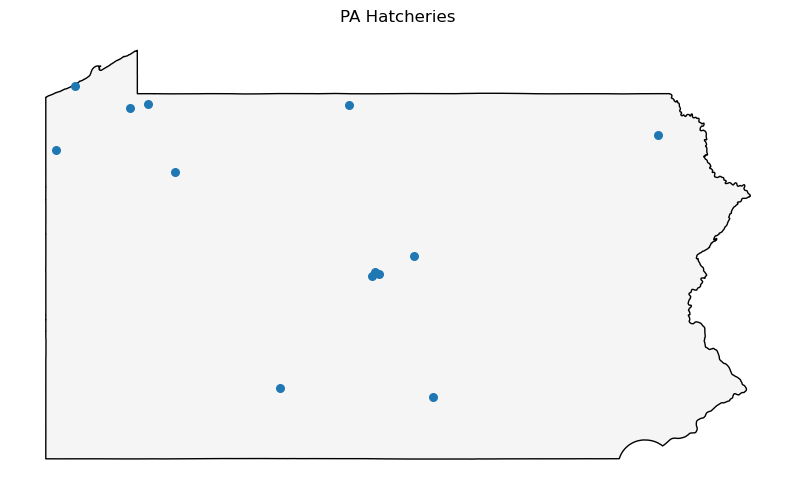

In [3]:

# 1. Load both layers
pa = gpd.read_file("../data/raw/pa_boundary.gpkg")
hatch = gpd.read_file("../data/raw/pa_hatcheries.gpkg")

# 2. Match the CRS (always before overlaying)
hatch = hatch.to_crs(pa.crs)

# 3. Plot
fig, ax = plt.subplots(figsize=(10, 6))
#Basemap
pa.plot(ax=ax, color="whitesmoke", edgecolor="black")
#Hatcheries
hatch.plot(ax=ax, color="tab:blue", markersize=30)

ax.set_title("PA Hatcheries")
ax.set_axis_off()
fig.savefig(f"{FIG_DIR}/pa_hatcheries_all.png", dpi=200, bbox_inches="tight")


In [4]:
# Review hatcheries data

hatch.info()

<class 'geopandas.geodataframe.GeoDataFrame'>
RangeIndex: 13 entries, 0 to 12
Data columns (total 14 columns):
 #   Column      Non-Null Count  Dtype   
---  ------      --------------  -----   
 0   REGION      13 non-null     object  
 1   ID          13 non-null     int32   
 2   COUNTY      13 non-null     object  
 3   FULL_NAME   13 non-null     object  
 4   NAME        13 non-null     object  
 5   VISITOR_CE  13 non-null     object  
 6   TROUT       13 non-null     object  
 7   WARM_COOL   13 non-null     object  
 8   STEEL_SALM  13 non-null     object  
 9   Link        13 non-null     object  
 10  Long_       13 non-null     float64 
 11  Lat         13 non-null     float64 
 12  County_Lin  13 non-null     object  
 13  geometry    13 non-null     geometry
dtypes: float64(2), geometry(1), int32(1), object(10)
memory usage: 1.5+ KB


In [5]:
# What does the data look like
print("First few rows of the hatcheries data:")
hatch.head()


First few rows of the hatcheries data:


,REGION,ID,COUNTY,FULL_NAME,NAME,VISITOR_CE,TROUT,WARM_COOL,STEEL_SALM,Link,Long_,Lat,County_Lin,geometry
0,Southcentral,11,Bedford,Reynoldsdale State Fish Hatchery,Reynoldsdale,y,y,,,http://fishandboat.com/Fish/Stocking/StateFish...,-78.58000,40.15750,http://pfbc.maps.arcgis.com/apps/webappviewer/...,POINT (-78.58 40.15751)
1,Northcentral,8,Centre,Benner Spring State Fish Hatchery,Benner Spring,,y,y,,http://fishandboat.com/Fish/Stocking/StateFish...,-77.81694,40.85762,http://pfbc.maps.arcgis.com/apps/webappviewer/...,POINT (-77.81694 40.85763)
2,Northcentral,9,Centre,Bellefonte State Fish Hatchery,Bellefonte,y,y,,,http://fishandboat.com/Fish/Stocking/StateFish...,-77.79402,40.88273,http://pfbc.maps.arcgis.com/apps/webappviewer/...,POINT (-77.79402 40.88274)
3,Northcentral,7,Centre,Pleasant Gap State Fish Hatchery,Pleasant Gap,,y,,,http://fishandboat.com/Fish/Stocking/StateFish...,-77.75750,40.86878,http://pfbc.maps.arcgis.com/apps/webappviewer/...,POINT (-77.7575 40.86879)
4,Northcentral,10,Clinton,Tylersville State Fish Hatchery,Tylersville,,y,,,http://fishandboat.com/Fish/Stocking/StateFish...,-77.47062,40.98244,http://pfbc.maps.arcgis.com/apps/webappviewer/...,POINT (-77.47062 40.98245)


In [6]:
# Website shows 12 hatcheries with data. How many do we have in our dataset?
print("Number of hatcheries in the dataset:", hatch.shape[0])

# Print out the full list of names to compare to website
print("Names of hatcheries in the dataset:")
print(hatch["FULL_NAME"])

Number of hatcheries in the dataset: 13
Names of hatcheries in the dataset:
0       Reynoldsdale State Fish Hatchery
1      Benner Spring State Fish Hatchery
2         Bellefonte State Fish Hatchery
3       Pleasant Gap State Fish Hatchery
4        Tylersville State Fish Hatchery
5          Huntsdale State Fish Hatchery
6     Pleasant Mount State Fish Hatchery
7             Oswayo State Fish Hatchery
8           Fairview State Fish Hatchery
9              Corry State Fish Hatchery
10        Union City State Fish Hatchery
11        Linesville State Fish Hatchery
12          Tionesta State Fish Hatchery
Name: FULL_NAME, dtype: object


In [7]:
# Does the Trout column y/n explain the one extra? Perhaps a non-trout hatchery?

print("Values in the Trout column:")
non_trout = hatch[hatch["TROUT"] != "y"]
non_trout

Values in the Trout column:


,REGION,ID,COUNTY,FULL_NAME,NAME,VISITOR_CE,TROUT,WARM_COOL,STEEL_SALM,Link,Long_,Lat,County_Lin,geometry
8,Northwest,1,Erie,Fairview State Fish Hatchery,Fairview,,,,y,http://fishandboat.com/Fish/Stocking/StateFish...,-80.27630,42.04262,http://pfbc.maps.arcgis.com/apps/webappviewer/...,POINT (-80.2763 42.04263)
10,Northwest,3,Erie,Union City State Fish Hatchery,Union City,,,y,,http://fishandboat.com/Fish/Stocking/StateFish...,-79.81782,41.90750,http://pfbc.maps.arcgis.com/apps/webappviewer/...,POINT (-79.81782 41.90751)
12,Northwest,13,Forest,Tionesta State Fish Hatchery,Tionesta,y,,y,y,http://fishandboat.com/Fish/Stocking/StateFish...,-79.44988,41.50756,http://pfbc.maps.arcgis.com/apps/webappviewer/...,POINT (-79.44988 41.50757)


*Fairview* and *Union City* are not trout hatcheries: Fairview raises steelhead/salmon only, and Union City is a mussel hatchery (https://www.pa.gov/agencies/fishandboat/about-us/agency-overview/bureaus/field-operations/fisheries-management/union-city-aquatic-conservation-center). Neither appears on PFBC's 2026 stocking schedule.

*Tionesta* has a blank in the Trout column and no production/yield data on its website (https://www.pa.gov/agencies/fishandboat/about-us/agency-overview/bureaus/state-fish-hatcheries/tionesta-state-fish-hatchery), but PFBC's 2026 stocking schedule lists it as the hatchery for 10 stream sections (26 events, brown and rainbow trout). The blank is a data-entry error in the source layer, so it is corrected to `y` below (raw file untouched). Its production figure is still missing.

That gives 11 trout hatcheries for the project. Side note: interesting scenario where we imagine the two non-trout hatcheries (Fairview, Union City) are converted over and see how that changes our run.


In [8]:
# PFBC's hatchery layer has TROUT blank for Tionesta (a data-entry error in the source), but Tionesta does
# stock trout: PFBC's 2026 stocking schedule lists it as the hatchery for 10 stream sections (brown and rainbow).
# Correct the flag here. The raw file data/raw/pa_hatcheries.gpkg is left untouched.
hatch.loc[hatch["NAME"] == "Tionesta", "TROUT"] = "y"

# drop the non-trout hatcheries from the dataset
hatch_trout = hatch[hatch["TROUT"] == "y"]

hatch_trout.shape

(11, 14)

In [9]:
# Review hatcheries that are MORE than just trout hatcheries

mixed_hatcheries =  hatch_trout[(hatch_trout["WARM_COOL"] == "y") | (hatch_trout["STEEL_SALM"] == "y")]
mixed_hatcheries

,REGION,ID,COUNTY,FULL_NAME,NAME,VISITOR_CE,TROUT,WARM_COOL,STEEL_SALM,Link,Long_,Lat,County_Lin,geometry
1,Northcentral,8,Centre,Benner Spring State Fish Hatchery,Benner Spring,,y,y,,http://fishandboat.com/Fish/Stocking/StateFish...,-77.81694,40.85762,http://pfbc.maps.arcgis.com/apps/webappviewer/...,POINT (-77.81694 40.85763)
5,Southcentral,12,Cumberland,Huntsdale State Fish Hatchery,Huntsdale,y,y,y,,http://fishandboat.com/Fish/Stocking/StateFish...,-77.30833,40.10306,http://pfbc.maps.arcgis.com/apps/webappviewer/...,POINT (-77.30833 40.10307)
6,Northeast,6,Wayne,Pleasant Mount State Fish Hatchery,Pleasant Mount,y,y,y,,http://fishandboat.com/Fish/Stocking/StateFish...,-75.44806,41.73972,http://pfbc.maps.arcgis.com/apps/webappviewer/...,POINT (-75.44806 41.73973)
11,Northwest,2,Crawford,Linesville State Fish Hatchery,Linesville,y,y,y,y,http://fishandboat.com/Fish/Stocking/StateFish...,-80.42748,41.64583,http://pfbc.maps.arcgis.com/apps/webappviewer/...,POINT (-80.42748 41.64584)
12,Northwest,13,Forest,Tionesta State Fish Hatchery,Tionesta,y,y,y,y,http://fishandboat.com/Fish/Stocking/StateFish...,-79.44988,41.50756,http://pfbc.maps.arcgis.com/apps/webappviewer/...,POINT (-79.44988 41.50757)


## Which have specific trout data?

Benner Spring have production specific to trout

Huntsdale have production specific to trout

Pleasant Mount State is multiple fish in the number

Linesville State fish Hatchery has no data

Tionesta has no production figure (but it is on the 2026 stocking schedule)




C:\Users\loydg\anaconda3\Lib\site-packages\geopandas\geodataframe.py:1968: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  super().__setitem__(key, value)


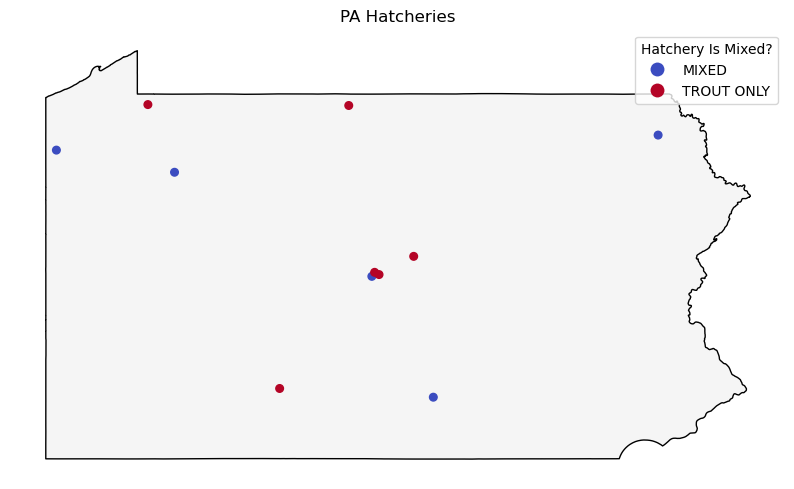

In [10]:
# Show trout only hatcheries versus mixed hatchers on the map (color distinguish)

# Create binary for trout only versus mixed hatcheries
# TRUE = mixed
hatch_trout["MIXED"] = (hatch_trout["WARM_COOL"] == "y") | (hatch_trout["STEEL_SALM"] == "y")

# Make MIXED = true be MIXED
hatch_trout["MIXED"] = hatch_trout["MIXED"].replace({True: "MIXED", False: "TROUT ONLY"})
fig, ax = plt.subplots(figsize=(10, 6))
#Basemap
pa.plot(ax=ax, color="whitesmoke", edgecolor="black")

# plot hatch_trout with color distinction for mixed vs trout only
hatch_trout.plot(ax=ax, column="MIXED", cmap="coolwarm", markersize=30, legend=True)

ax.set_title("PA Hatcheries")
ax.set_axis_off()
#add legend title
ax.get_legend().set_title("Hatchery Is Mixed?")
fig.savefig(f"{FIG_DIR}/pa_trout_hatcheries_mixed_vs_trout_only.png", dpi=200, bbox_inches="tight")

### Export hatch_trout to data/processed

In [11]:
# export hatch_trout to data/processed as gpkg
hatch_trout.to_file("../data/processed/trout_hatcheries.gpkg", driver="GPKG")

## Review production per hatchery

In [12]:
# Import in pa_hatchery_production.csv
hatchery_production = pd.read_csv("../data/raw/pa_hatchery_production.csv")

# review
print(hatchery_production)
print(hatchery_production.shape)

         hatchery  production_value                 production_units  \
0      Bellefonte          338918.0                              lbs   
1   Benner Spring          336366.0                              lbs   
2       Huntsdale          461280.0                              lbs   
3    Reynoldsdale          161932.0                              lbs   
4     Tylersville          372782.0                              lbs   
5           Corry          145851.0                              lbs   
6          Oswayo          181261.0                              lbs   
7    Pleasant Gap          256164.0                              lbs   
8  Pleasant Mount        25963170.0  count (fry/fingerling/yearling)   
9      Linesville               NaN                              NaN   

                                       label_on_page  \
0                           Average Trout Production   
1                           Average Trout Production   
2                           Average Tro

In [13]:
# Sum total of production after filtering out NAs and "PLeasant Mount" 
total_production = hatchery_production[
    (hatchery_production["production_value"].notnull()) &
    (hatchery_production["hatchery"] != "Pleasant Mount")
]["production_value"].sum()

# Print formatted with commas
total_production_formatted = "{:,.0f}".format(total_production)
print(f"Total production: {total_production_formatted}")

Total production: 2,254,554


In [14]:
# Hatchery overview for the report: the 10 trout hatcheries, mixed flag, and production
hatchery_overview = (
    hatch_trout[["ID", "NAME", "COUNTY", "REGION", "MIXED"]]
    .merge(
        hatchery_production[["hatchery", "production_value", "production_units", "label_on_page"]],
        left_on="NAME", right_on="hatchery", how="left", validate="one_to_one",
    )
    .drop(columns="hatchery")
    .sort_values("production_value", ascending=False)
    .reset_index(drop=True)
)
hatchery_overview.to_csv(f"{TABLE_DIR}/trout_hatchery_overview.csv", index=False)
hatchery_overview

,ID,NAME,COUNTY,REGION,MIXED,production_value,production_units,label_on_page
0,6,Pleasant Mount,Wayne,Northeast,MIXED,25963170.0,count (fry/fingerling/yearling),Average Fish Production (species not stated on...
1,12,Huntsdale,Cumberland,Southcentral,MIXED,461280.0,lbs,Average Trout Production
2,10,Tylersville,Clinton,Northcentral,TROUT ONLY,372782.0,lbs,Average Trout Production
3,9,Bellefonte,Centre,Northcentral,TROUT ONLY,338918.0,lbs,Average Trout Production
4,8,Benner Spring,Centre,Northcentral,MIXED,336366.0,lbs,Average Trout Production
5,7,Pleasant Gap,Centre,Northcentral,TROUT ONLY,256164.0,lbs,Average Fish Production (species not stated on...
6,5,Oswayo,Potter,Northcentral,TROUT ONLY,181261.0,lbs,Average Fish Production (species not stated on...
7,11,Reynoldsdale,Bedford,Southcentral,TROUT ONLY,161932.0,lbs,Average Trout Production
8,4,Corry,Erie,Northwest,TROUT ONLY,145851.0,lbs,Average Fish Production (species not stated on...
9,2,Linesville,Crawford,Northwest,MIXED,NaN,NaN,No production figure found on page


## Overlay Streams

In [15]:
# Import streams for maps

class_a = gpd.read_file("../data/raw/pa_class_a_trout_streams.gpkg")

pa_stocked = gpd.read_file("../data/raw/pa_stocked_trout_streams.gpkg")



In [16]:
class_a.sample(20)

,WtrLatDD,WtrLonDD,SecNum,SecSubbasi,SecCnt1Per,SecCnt2Per,SecUpperLi,SecLowerLi,Length_ft,Length_MI_GIS,...,GIS_Key,COUNTY_NAM,Region,MapID,GlobalID,Fishery,Region_2,MapID_2,RFP_WaterID,geometry
776,39.968056,-79.513333,1,19,NaN,NaN,29.719999,24.360001,32743.914600,6.201499,...,6215-1,Westmoreland,Southwest,53.0,{6F97D361-1C33-42C4-8533-84392D47AEBB},Wild Brown Trout Fishery,None,NaN,6215,"MULTILINESTRING ((-79.22851 40.10644, -79.2292..."
436,41.549444,-77.553889,1,9,0.0,0.0,6.840000,0.620000,20300.605435,3.844812,...,3623-1,Tioga,Northcentral,169.0,{E54E0D96-C2EE-4E27-8CEC-98586C5CD074},Mixed Brook/Brown,None,NaN,3623,"MULTILINESTRING ((-77.54993 41.60852, -77.5499..."
547,40.819722,-77.626944,2,6,100.0,NaN,4.040000,0.000000,NaN,4.023530,...,2465-2,Centre,Northcentral,243.0,{913015B0-9D9A-4214-BD66-7EB910F08CC9},Brown,None,NaN,2465,"MULTILINESTRING ((-77.61978 40.7757, -77.61979..."
731,41.003987,-77.387828,1,9,100.0,NaN,1.570000,0.540000,8436.460286,1.597814,...,5429-1,Clinton,Northcentral,324.0,{F6570EDE-B63B-42C9-835D-3A4260CD0FAC},Wild Brook Trout Fishery,None,NaN,5429,"MULTILINESTRING ((-77.35905 40.99039, -77.3601..."
10,41.741111,-77.578056,2,9,0.0,0.0,5.300000,0.000000,28963.832971,5.485574,...,3586-2,Tioga,Northcentral,171.0,{6A7FF39C-85D7-4A82-A281-FE7687AC944D},Brown,None,NaN,3586,"MULTILINESTRING ((-77.54126 41.68233, -77.5414..."
1011,40.930833,-77.816944,1,9,NaN,NaN,10.000000,5.440000,32436.761296,6.143326,...,2522-1,Centre,Northcentral,523.0,{A3E9B29F-1910-42B8-BAD7-1C50A1C3B22E},Mixed Brook/Brown Trout Fishery,None,NaN,2522,"MULTILINESTRING ((-77.95743 40.93161, -77.9573..."
42,40.593611,-77.576389,6,12,100.0,0.0,4.500000,1.930000,13293.814223,2.517768,...,2628-6,Mifflin,Southcentral,27.0,{E2738665-94D1-4508-B8B6-36C203D34A82},Brown,None,NaN,2628,"MULTILINESTRING ((-77.57468 40.63845, -77.5743..."
40,41.796111,-77.480833,1,9,100.0,0.0,3.900000,0.000000,18510.619150,3.505799,...,3489-1,Tioga,Northcentral,162.0,{879BFF92-FA49-4A5F-9E36-B2FE1D3F24DF},Brook,None,NaN,3489,"MULTILINESTRING ((-77.522 41.82003, -77.52137 ..."
1076,41.231507,-77.619080,1,9,NaN,NaN,1.600000,0.000000,8804.950338,1.667604,...,5327-1,Clinton,Northcentral,NaN,{130A025B-09DC-4704-AC0D-89343E467D75},Wild Brook Trout Fishery,None,NaN,5327,"MULTILINESTRING ((-77.62899 41.2112, -77.629 4..."
1241,41.113888,-75.223055,3,1,100.0,NaN,0.400000,0.000000,2675.961154,0.506811,...,2440-3,Monroe,Northeast,NaN,{B5E3E727-52CC-4181-845A-6E7E809229D4},Mixed Brook/Brown Trout Fishery,None,NaN,2440,"MULTILINESTRING ((-75.21917 41.11966, -75.2192..."


In [17]:
# How many setions in the class a streams
class_a.shape[0]

1361

In [18]:
pa_stocked.sample(20)

,GNIS_ID,Length_MI_,Mid_Lat,Mid_Long,OBJECTID,GNIS_Name,County,Year_Round,Early_Open,Region,...,Limits,EarlyOpen_Desc,WtrLatLon,UniqueID,RFP_WaterID,GIS_Key,Reg_Name,Reg_Link,GlobalID,geometry
425,1199246.0,8.128908,41.767680,-79.792030,434,Oil Creek,Crawford,N,None,Northwest,...,CONFL OF MOSEY RUN NEAR LIN'VL down to CONF E ...,None,412556794234,82.0,1909,1909-2,Stocked Trout Water,﻿https://www.pa.gov/content/dam/copapwp-pagov/...,{37B2970C-208F-45D1-B725-ACB4DB3F13F2},"MULTILINESTRING ((-79.84026 41.7955, -79.84023..."
878,1182264.0,12.568032,41.041110,-80.314070,896,Neshannock Creek,Lawrence,N,None,Northwest,...,T-476 (COVERED BRIDGE) downstream to Mouth,None,405935802115,50.0,329,329-5,Stocked Trout Water,﻿https://www.pa.gov/content/dam/copapwp-pagov/...,{3B0DEEFB-DC07-401B-AA56-A50A838B8D02},"MULTILINESTRING ((-80.28731 41.09178, -80.2879..."
242,1209733.0,1.494082,41.752754,-78.685197,247,Kinzua Creek,McKean,N,None,Northcentral,...,ANF BOUNDARY down to GUFFEY ROAD BRIDGE,None,414628785103,165.0,2634,2634-3,Stocked Trout Water,﻿https://www.pa.gov/content/dam/copapwp-pagov/...,{CB171A6C-098E-4CB6-858F-8FE38CE16B69},"MULTILINESTRING ((-78.67606 41.74614, -78.6763..."
1020,1183625.0,5.400584,40.284972,-79.933745,1038,Peters Creek,Allegheny,N,None,Southwest,...,MOUTH OF PINEY FORK down to BEND DS OF MONTOUR...,None,401834795254,NaN,2068,2068-2,Stocked Trout Water,﻿https://www.pa.gov/content/dam/copapwp-pagov/...,{34C961B8-5322-4279-A34B-E29457AA6BE3},"MULTILINESTRING ((-79.96895 40.27171, -79.9688..."
393,1173739.0,2.671092,39.829990,-76.646850,402,East Branch Codorus Creek,York,N,None,Southcentral,...,FIRST UNT DNST S BDY CTY PARK down to SR 216 B...,None,395346764437,495.0,232,232-2,Stocked Trout Water,﻿https://www.pa.gov/content/dam/copapwp-pagov/...,{F6C93497-AE93-4994-B42E-7F63E9C48C91},"MULTILINESTRING ((-76.64854 39.81699, -76.6487..."
377,1210192.0,9.998200,41.745750,-78.532980,386,Marvin Creek,McKean,N,None,Northcentral,...,T450 BRDG @ HAZLEHURST down to POWERLINE DNST ...,None,414830782550,166.0,2645,2645-2,Stocked Trout Water,﻿https://www.pa.gov/content/dam/copapwp-pagov/...,{3EF0C51A-2B91-47A4-B8EE-F607E6749DA5},"MULTILINESTRING ((-78.58449 41.7065, -78.58397..."
329,1199898.0,17.288017,41.418483,-80.275274,337,Little Shenango River,Mercer,N,None,Northwest,...,SR1009 (LAKE WILHELM RD.) BRDG down to CONFLUE...,None,412421802335,48.0,354,354-2,Stocked Trout Water,﻿https://www.pa.gov/content/dam/copapwp-pagov/...,{B6DD1E0F-65F5-4E21-B901-EF0AA482EB93},"MULTILINESTRING ((-80.18436 41.39548, -80.1843..."
1033,1187488.0,6.087861,40.315570,-77.544394,1051,Sherman Creek,Perry,N,None,Southcentral,...,LOWER TUSCARORA ST FOREST BNDY down to SR3004 ...,None,402301770143,734.0,3306,3306-2,Stocked Trout Water,﻿https://www.pa.gov/content/dam/copapwp-pagov/...,{0FFAE340-C328-4D51-B9E7-6002572E22A1},"MULTILINESTRING ((-77.58564 40.29969, -77.5853..."
681,1169182.0,3.662436,40.607015,-78.359307,694,Bells Gap Run,Blair,N,None,Southcentral,...,BELLWOOD RS down to MOUTH,None,403539782015,823.0,6062,6062-2,Stocked Trout Water,﻿https://www.pa.gov/content/dam/copapwp-pagov/...,{3D71C39F-F220-4725-BF30-138925FD5F76},"MULTILINESTRING ((-78.38284 40.62252, -78.3825..."
698,1181004.0,1.038292,41.233352,-75.108429,711,Middle Branch Creek,Pike,N,None,Northeast,...,STATE FOREST BOUNDARY down to CONFL W/BUSHKILL CK,None,411344750617,361.0,2476,2476-2,Stocked Trout Water,﻿https://www.pa.gov/content/dam/copapwp-pagov/...,{3A752EDE-7289-4C59-901C-4124A7C39C11},"MULTILINESTRING ((-75.1116 41.23998, -75.1115 ..."


In [19]:
# How many sections in the stocked streams

pa_stocked.shape[0]

1064

In [20]:
pa_stocked['GNIS_Name'].value_counts()

GNIS_Name
Pine Creek         21
Kettle Creek       12
Fishing Creek      10
Buffalo Creek       8
Oil Creek           7
                   ..
Enlow Fork          1
Carbaugh Run        1
Bell Run            1
Pennypack Creek     1
Peters Creek        1
Name: count, Length: 611, dtype: int64

In [21]:
# Confirm primary key
pa_stocked['GlobalID'].value_counts()

GlobalID
{E87192C0-AF69-4A17-A73C-922F086F4A73}    1
{DC3ED7FD-CEAD-4AF6-A01C-7D00385B075C}    1
{C00E4BD8-42B5-4E7A-8B0D-FC26018CBDE8}    1
{AD51CB88-DE8C-459D-9C70-9BE912BDEDB2}    1
{702A2916-2CA2-4044-9A51-DE46D2A7AEE7}    1
                                         ..
{250C2727-9234-4472-8E4C-B286263BFE86}    1
{74E6E903-7142-4276-A306-463928EF549C}    1
{53761219-BA71-424F-A6B1-CAD36EED663D}    1
{BB772EC8-6518-42C6-8C51-0C5B020EA461}    1
{1DB3B10C-9DDF-4CD7-A06E-7886AF497A1F}    1
Name: count, Length: 1064, dtype: int64

### Nurseries

In [22]:
# import from raw data the coop_nurseries
coop_nurseries = gpd.read_file("../data/raw/Coop_nurseries.geojson")

coop_nurseries.sample(20)



,LAT,LONG_,GlobalID,OBJECTID_1,NURSERY_NA,SPONSOR_NA,COUNTY,REGION,OPEN_DATE,ID,geometry
62,41.13,-76.22,{6CE075F6-E8C3-490A-8E49-A64064BC542A},2045,Fishingcreek,Fishingcreek Sportsmen Assoc. ...,Columbia,NORTHEAST,1969,58,POINT (-76.22168 41.12548)
119,40.85,-75.77,{BD40ADE0-9FCE-4FDE-BF79-02404938C51F},2102,Jim Thorpe,Jim Thorpe Sportsmen Club ...,Carbon,NORTHEAST,1994,83,POINT (-75.7745 40.85227)
114,39.94,-75.42,{B6127FDD-4CC8-4085-ABA3-751077E9183D},2097,Delco Anglers & Conservationists,Delco Anglers & Conservationists ...,Delaware,SOUTHEAST,1965,46,POINT (-75.41937 39.94204)
22,41.18,-78.04,{1DD00839-9C88-4652-8AB2-DC2D8828CF8E},2005,Wycoff Run,"Wycoff Run Fish Nursery, Inc. ...",Cameron,NORTHCENTRAL,1987,177,POINT (-78.04426 41.18473)
125,41.90,-80.36,{CB2D66AE-99FE-41C0-B6DE-B0A535E92DAF},2108,"Albion Sportsmen Club, Inc","Albion Sportsmen Club, Inc. ...",Erie,NORTHWEST,1969,11,POINT (-80.35933 41.90253)
11,39.80,-79.33,{0FD72B22-EBAB-410A-8487-91E0013CCD92},1994,Turkeyfoot Valley Area High School,Salisbury-Elklick Hunting Club ...,Somerset,SOUTHWEST,2023,220,POINT (-79.33032 39.79831)
83,40.64,-76.55,{90C0636D-ED18-424D-B066-068E59A2997B},2066,Pine Creek Trout Nursery (Valley View),Valley View Gun Club ...,Schuylkill,SOUTHEAST,1974,169,POINT (-76.54825 40.63851)
75,41.85,-77.49,{86F22A01-3CAC-4233-88BA-0FD9482F3A02},2058,C.V. Anglers Club,C.V. Anglers Club ...,Tioga,NORTHCENTRAL,1971,28,POINT (-77.48899 41.85079)
3,39.92,-79.16,{0638704B-AD46-4D1B-A620-84A240284118},1986,Rockwood High School FFA,Salisbury-Elklick Hunting Club ...,Somerset,SOUTHWEST,2016,200,POINT (-79.16167 39.91779)
7,42.03,-80.30,{09A54765-3E3F-4F36-9BAA-57965683FB04},1990,Ro-Ze,3 C.U. Trout Assoc. ...,Erie,NORTHWEST,1966,7,POINT (-80.30216 42.03025)
